# Purchase-model training and pickle example

Train a simple linear regression on the supplied **purchase decisions** and save it for the pricing examples. The model estimates purchase probability from covariates and the offered price.

In [1]:
from pathlib import Path
import os
import sys

# Resolve paths once so every notebook uses the project folder.
project_folder = next((
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / 'project_code_2026_publicshare',
                   parent / 'project_2026/project_code_2026_publicshare',
                   parent / 'private_github/project_2026/project_code_2026_publicshare')
    if (folder / 'pricing_helpers.py').is_file()
), None)
if project_folder is None:
    raise FileNotFoundError('Open the project folder as your notebook workspace.')
os.chdir(project_folder)
sys.path.insert(0, str(project_folder))

import pickle
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

data = pd.read_csv(project_folder / 'data/train_prices_decisions_2026.csv')

import xgboost
from xgboost import XGBClassifier

In [2]:
print(data.shape)
data.head()
data.describe()
data['item_bought'].value_counts(normalize=True)

(50000, 6)


item_bought
False    0.5753
True     0.4247
Name: proportion, dtype: float64

In [3]:
features = ['Covariate1', 'Covariate2', 'Covariate3', 'price_item']
train, test = train_test_split(data, test_size=.2, random_state=0)
model = LinearRegression().fit(train[features], train.item_bought.astype(float))
# Clip regression predictions to [0, 1]. For a classifier, you may
# need predict_proba() instead of predict(), using the column for purchase = 1.
purchase_probability = np.clip(model.predict(test[features]), 0, 1)
print('Held-out mean squared error:', np.mean((purchase_probability-test.item_bought)**2))


Held-out mean squared error: 0.17095434766778153


In [4]:
# 100 decision trees, depth 3, learning rate 0.1, single-threaded for reproducibility
xgb_model = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=0, n_jobs=1)

features = ['Covariate1', 'Covariate2', 'Covariate3', 'price_item']
X_train = train[features]
y_train = train['item_bought']

X_test = test[features]
y_test = test['item_bought']

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=1, num_parallel_tree=None, ...)

In [5]:
from sklearn.metrics import mean_squared_error

xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
xgb_mse = mean_squared_error(y_test, xgb_probs)

print("XGBoost MSE:", xgb_mse)

XGBoost MSE: 0.04478611424565315


In [6]:
train_probs = xgb_model.predict_proba(X_train)[:, 1]
train_mse = mean_squared_error(y_train, train_probs)

print("Train MSE:", train_mse)
print("Test MSE:", xgb_mse)

Train MSE: 0.04288562014698982
Test MSE: 0.04478611424565315


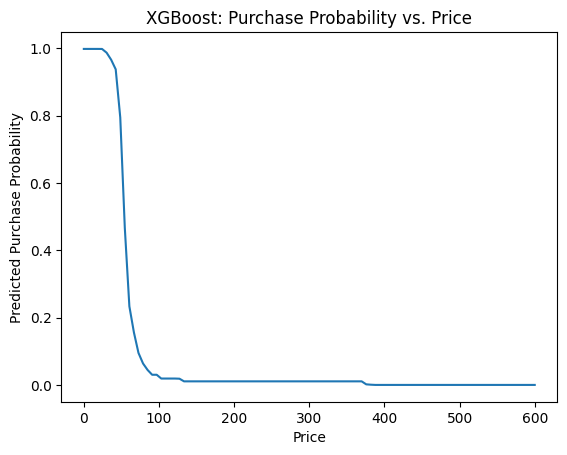

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

prices = np.linspace(data['price_item'].min(), data['price_item'].max(), 100)

customer = X_test.iloc[0]
price_data = pd.DataFrame([customer] * len(prices))
price_data['price_item'] = prices

purchase_probs = xgb_model.predict_proba(price_data)[:, 1]

plt.plot(prices, purchase_probs)
plt.xlabel('Price')
plt.ylabel('Predicted Purchase Probability')
plt.title('XGBoost: Purchase Probability vs. Price')
plt.show()

In [8]:
expected_revenue = prices * purchase_probs

best_idx = np.argmax(expected_revenue)

print("Optimal price:", prices[best_idx])
print("Expected revenue:", expected_revenue[best_idx])

Optimal price: 42.42589017059269
Expected revenue: 39.75725587355095


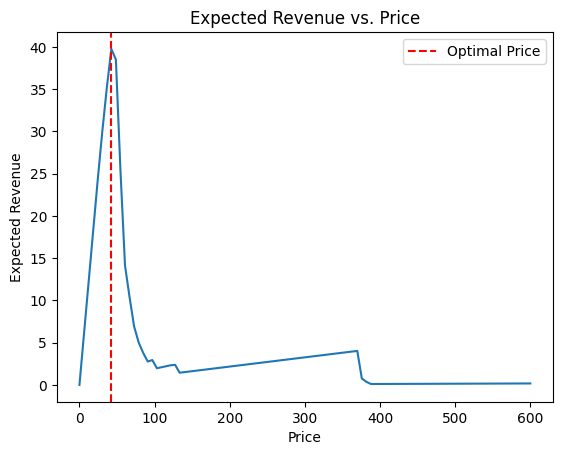

In [9]:
plt.plot(prices, expected_revenue)
plt.axvline(prices[best_idx], color='red', linestyle='--', label='Optimal Price')
plt.xlabel('Price')
plt.ylabel('Expected Revenue')
plt.title('Expected Revenue vs. Price')
plt.legend()
plt.show()

## Save and reload the model

Commit your training code here and the saved model in `agents/helper_files_here/`. Both `agents/agent_part1.py` and `agents/agent_part2.py` load this model.


In [10]:
# Refit XGBoost on all 50,000 training observations
xgb_model.fit(data[features], data["item_bought"])

model_path = project_folder / "agents/helper_files_here/xgb_model.pkl"
model_path.parent.mkdir(parents=True, exist_ok=True)

with model_path.open("wb") as file:
    pickle.dump(xgb_model, file)

with model_path.open("rb") as file:
    loaded_model = pickle.load(file)

print("Saved XGBoost model:", model_path)

Saved XGBoost model: /Users/mikhail/Documents/GitHub/_Cornell/ORIE5355/project_secret/agents/helper_files_here/xgb_model.pkl


In [11]:
example = test[features].iloc[:5]
probability = loaded_model.predict_proba(example)[:, 1]
example.assign(predicted_purchase_probability=probability,
               predicted_revenue=example.price_item*probability)

,Covariate1,Covariate2,Covariate3,price_item,predicted_purchase_probability,predicted_revenue
11841,1.0,5.786335,8.745733,84.660771,0.061137,5.175918
19602,0.0,3.061094,6.233968,247.119267,0.000813,0.201018
45519,1.0,0.764292,5.543483,28.843204,0.994709,28.690588
25747,0.0,3.361321,4.995297,27.821668,0.965013,26.848259
42642,0.0,1.329455,7.347017,113.482735,0.001856,0.210677


In [12]:
# Approximate future customer demand
covariates = ["Covariate1", "Covariate2", "Covariate3"]
price_grid = np.linspace(0, 500, 101)

sample = data[covariates].sample(n=500, random_state=42)

X = pd.DataFrame(
    np.repeat(sample.to_numpy(), len(price_grid), axis=0),
    columns=covariates
)
X["price_item"] = np.tile(price_grid, len(sample))

q = loaded_model.predict_proba(X[features])[:, 1]
q = q.reshape(len(sample), len(price_grid))

# Bellman dynamic programming
# t = customers remaining; s = inventory remaining
V = np.zeros((21, 21))

for t in range(1, 21):
    for s in range(1, 21):

        opportunity_cost = V[t-1, s] - V[t-1, s-1]

        score = q * (price_grid[None, :] - opportunity_cost)

        V[t, s] = V[t-1, s] + score.max(axis=1).mean()

# Save the Bellman table
bellman_path = project_folder / "agents/helper_files_here/bellman_values_xgb.npy"

np.save(bellman_path, V)

print("Saved Bellman table:", V.shape)

Saved Bellman table: (21, 21)
